# Fine-tuning supervisé (SFT) de Qwen3-1.7B-Base avec LoRA

On apprend au modèle à répondre comme dans nos exemples : questions d'examen, questions de patients et cas de triage. Avec LoRA, seules de petites matrices ajoutées au modèle sont entraînées, ce qui tient sur la carte graphique du PC (RTX 4070 SUPER, 12 Go).

Outils : TRL (`SFTTrainer`) pour la boucle d'entraînement, PEFT pour LoRA, MLflow pour garder la trace de chaque run. Unsloth, proposé dans les ressources, demande des versions de torch, transformers et datasets plus anciennes que celles du projet : on s'en passe.

Démarche :
- un petit run sur 200 exemples pour valider la chaîne
- deux runs complets avec deux learning rates
- on garde le meilleur checkpoint sur la validation

Les jeux de test ne servent pas ici, ils sont gardés pour le notebook 06.

In [1]:
import gc
import json
import shutil
import statistics
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import torch
from datasets import concatenate_datasets, load_dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

SEED = 42
MODEL = "Qwen/Qwen3-1.7B-Base"
DATA_REPO, DATA_REVISION = "g-hostin/medical-triage-poc-data", "v1.1"
OUT_DIR = Path("../models/sft")

set_seed(SEED)
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("sft")
print(torch.cuda.get_device_name(0), "|", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "Go")

C:\Users\gregh\Desktop\OpenClassrooms\AI Engineer\P14\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/11/16 15:37:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/16 15:37:51 INFO mlflow.store.db.utils: Updating database tables


2026/11/16 15:37:54 INFO mlflow.tracking.fluent: Experiment with name 'sft' does not exist. Creating a new experiment.


NVIDIA GeForce RTX 4070 SUPER | 12.9 Go


## 1. Les données

On charge la version 1.1 du jeu publié sur Hugging Face. L'étiquette `v1.1` fixe exactement les données utilisées : l'entraînement pourra être refait à l'identique.

Entraînement : les 4 500 exemples du SFT et les cas de triage. Le jeu de triage n'a pas de partie validation, on met donc de côté 40 de ses 400 cas d'entraînement pour que la validation contienne aussi du triage.

In [2]:
sft = load_dataset(DATA_REPO, "sft", revision=DATA_REVISION)
triage = load_dataset(DATA_REPO, "triage", revision=DATA_REVISION)

triage_train = triage["train"].shuffle(seed=SEED)
triage_val, triage_train = triage_train.select(range(40)), triage_train.select(range(40, len(triage_train)))

# seule la conversation sert à l'entraînement, pas les métadonnées
train_raw = concatenate_datasets([sft["train"].select_columns(["messages"]), triage_train.select_columns(["messages"])])
val_raw = concatenate_datasets([sft["validation"].select_columns(["messages"]), triage_val.select_columns(["messages"])])
print("entraînement :", len(train_raw), "| validation :", len(val_raw))

entraînement : 4860 | validation : 290


## 2. Le format des exemples

Le tokenizer de Qwen3 contient un gabarit de conversation (ChatML) qui termine chaque réponse par le marqueur `<|im_end|>`. Le modèle de base ne l'a presque jamais vu. On le vérifie sur 30 exemples de validation : après la réponse complète, quelle chance donne-t-il à `<|im_end|>`, et à `<|endoftext|>`, son marqueur habituel de fin de texte ?

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL)
base = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16, device_map="cuda")
im_end, end_of_text = tokenizer.convert_tokens_to_ids(["<|im_end|>", "<|endoftext|>"])

chances = {"<|im_end|>": [], "<|endoftext|>": []}
for row in val_raw.select(range(30)):
    question, answer = row["messages"]
    text = tokenizer.apply_chat_template([question], tokenize=False, add_generation_prompt=True) + answer["content"]
    ids = tokenizer(text, return_tensors="pt").input_ids.to("cuda")
    with torch.no_grad():
        probs = torch.softmax(base(ids).logits[0, -1].float(), dim=-1)
    chances["<|im_end|>"].append(probs[im_end].item())
    chances["<|endoftext|>"].append(probs[end_of_text].item())

for token, values in chances.items():
    print(f"{token} : chance médiane {statistics.median(values):.2e}")
del base
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   6%|▋         | 20/310 [00:00<00:02, 140.79it/s]

Loading weights:  11%|█▏        | 35/310 [00:00<00:02, 136.83it/s]

Loading weights:  17%|█▋        | 53/310 [00:00<00:01, 136.26it/s]

Loading weights:  23%|██▎       | 70/310 [00:00<00:01, 145.29it/s]

Loading weights:  28%|██▊       | 86/310 [00:00<00:01, 147.12it/s]

... (8 outputs left out)

Loading weights:  89%|████████▉ | 276/310 [00:01<00:00, 196.84it/s]

Loading weights:  96%|█████████▌| 298/310 [00:01<00:00, 196.59it/s]

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 178.90it/s]

<|im_end|> : chance médiane 2.02e-09
<|endoftext|> : chance médiane 6.14e-02


Le modèle de base donne environ 6 % à `<|endoftext|>` et une chance quasi nulle à `<|im_end|>`. Un premier essai avec `<|im_end|>` comme fin de réponse, fait avant ce notebook, donnait un modèle qui ne s'arrêtait jamais : réponses en boucle ou terminées par des caractères chinois. LoRA ne modifie pas la table des mots du modèle, et la version de TRL utilisée ne permet pas d'entraîner ces deux marqueurs.

On garde donc le gabarit pour la question, et la réponse en texte simple. Pour ce format, TRL ajoute lui-même `<|endoftext|>` à la fin de chaque réponse, et ne calcule la perte que sur la réponse.

In [4]:
def to_prompt_completion(row):
    question, answer = row["messages"]
    prompt = tokenizer.apply_chat_template([question], tokenize=False, add_generation_prompt=True)
    return {"prompt": prompt, "completion": answer["content"]}


train_ds = train_raw.map(to_prompt_completion, remove_columns=["messages"]).shuffle(seed=SEED)
val_ds = val_raw.map(to_prompt_completion, remove_columns=["messages"])
print(train_ds[0]["prompt"] + train_ds[0]["completion"][:200])

lengths = [len(tokenizer(r["prompt"] + r["completion"]).input_ids) + 1 for r in train_ds]
print("\nlongueur en tokens : médiane", int(statistics.median(lengths)), "| max", max(lengths))

<|im_start|>user
What are the symptoms of Penoscrotal transposition ?<|im_end|>
<|im_start|>assistant
What are the signs and symptoms of Penoscrotal transposition? The Human Phenotype Ontology provides the following list of signs and symptoms for Penoscrotal transposition. If the information is availa



longueur en tokens : médiane 217 | max 1183


Les exemples les plus longs (des cas de triage) dépassent les 1 024 tokens, la valeur par défaut de TRL. On fixe la longueur maximale à 1 280 pour ne couper aucune réponse.

## 3. Les réglages

Point de départ : le notebook Unsloth de SFT sur Qwen3 et le cours Hugging Face.
- LoRA de rang 16 sur toutes les couches linéaires, `lora_alpha` = 2 × rang (conseil du cours), `lora_dropout` de 0,05 contre le sur-apprentissage
- paquets de 8 exemples (2 à la fois, accumulés 4 fois : avec 4 à la fois, les exemples les plus longs saturaient la mémoire de la carte)
- une évaluation sur la validation et une sauvegarde (checkpoint) tous les 100 pas, en gardant le meilleur checkpoint
- graine fixée, réglages et courbes enregistrés dans MLflow

TRL active par défaut le gradient checkpointing (il recalcule une partie des calculs au lieu de les garder en mémoire). Sans lui, la mémoire de la carte est saturée et l'entraînement devient beaucoup plus lent.

In [5]:
MAX_LENGTH = 1280
LORA = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")


def train_run(name, train_data, val_data, learning_rate, epochs, eval_steps=100):
    model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16)
    args = SFTConfig(
        output_dir=str(OUT_DIR / name),
        run_name=name,
        max_length=MAX_LENGTH,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,
        per_device_eval_batch_size=4,
        learning_rate=learning_rate,
        num_train_epochs=epochs,
        warmup_steps=30,
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=eval_steps,
        save_strategy="steps",
        save_steps=eval_steps,
        save_total_limit=2,
        load_best_model_at_end=True,  # recharge le checkpoint qui a la plus petite perte de validation
        seed=SEED,
        report_to="mlflow",
    )
    trainer = SFTTrainer(model=model, args=args, train_dataset=train_data, eval_dataset=val_data,
                         processing_class=tokenizer, peft_config=LORA)
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"dataset": DATA_REPO, "dataset_revision": DATA_REVISION, "n_train": len(train_data),
                           "n_val": len(val_data), "lora_r": LORA.r, "lora_alpha": LORA.lora_alpha})
        # en cas d'arrêt, trainer.train(resume_from_checkpoint=True) reprend au dernier checkpoint
        trainer.train()
    trainer.save_model(OUT_DIR / name / "best")
    summary = {"name": name, "learning_rate": learning_rate, "epochs": epochs,
               "best_checkpoint": Path(trainer.state.best_model_checkpoint).name,
               "best_eval_loss": trainer.state.best_metric, "minutes": (time.time() - start) / 60,
               "memory_gb": torch.cuda.max_memory_allocated() / 1e9, "history": trainer.state.log_history}
    print(f"{name} : {summary['minutes']:.1f} min, mémoire max {summary['memory_gb']:.1f} Go")
    print(f"meilleur checkpoint : {summary['best_checkpoint']}, perte de validation {summary['best_eval_loss']:.3f}")
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return summary

## 4. Petit run

200 exemples d'entraînement, 40 de validation, une époque. On vérifie d'abord ce que le modèle apprend vraiment : TRL met à -100 les tokens de la question, qui sont ignorés dans le calcul de la perte.

In [6]:
small_train, small_val = train_ds.select(range(200)), val_ds.select(range(40))

check = SFTTrainer(model=AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16),
                   args=SFTConfig(output_dir=str(OUT_DIR / "check"), max_length=MAX_LENGTH, report_to="none"),
                   train_dataset=small_train.select(range(1)), processing_class=tokenizer, peft_config=LORA)
example = check.train_dataset[0]
print("appris :", tokenizer.decode([t for t in example["labels"] if t != -100]))
check.model.print_trainable_parameters()
del check
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 9/310 [00:00<00:04, 70.19it/s]

Loading weights:   5%|▌         | 17/310 [00:00<00:05, 55.68it/s]

Loading weights:   7%|▋         | 23/310 [00:00<00:06, 45.88it/s]

Loading weights:   9%|▉         | 28/310 [00:00<00:07, 36.43it/s]

Loading weights:  10%|█         | 32/310 [00:00<00:09, 30.21it/s]

... (2 outputs left out)

Loading weights:  15%|█▌        | 47/310 [00:01<00:07, 36.09it/s]

Loading weights:  16%|█▋        | 51/310 [00:01<00:07, 36.58it/s]

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 210.46it/s]

appris : What are the signs and symptoms of Penoscrotal transposition? The Human Phenotype Ontology provides the following list of signs and symptoms for Penoscrotal transposition. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Symptoms Approximate number of patients (when available) Absent facial hair - Elevated follicle stimulating hormone - Elevated luteinizing hormone - Female external genitalia in individual with 46,XY karyotype - Growth abnormality - Gynecomastia - Inguinal hernia - Neoplasm - Primary amenorrhea - Sparse axillary hair - Sparse pubic hair - X-linked recessive inheritance - The Human Phenotype Ontology (HPO) has collected information on how often a sign or symptom occurs in a condition. Much of this information comes from Orphanet, a European rare disease database. The frequency of a sig

In [7]:
small = train_run("petit_run", small_train, small_val, learning_rate=2e-4, epochs=1, eval_steps=10)
print([(h["step"], round(h["eval_loss"], 3)) for h in small["history"] if "eval_loss" in h])

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 10/310 [00:00<00:03, 94.09it/s]

Loading weights:   6%|▋         | 20/310 [00:00<00:04, 64.10it/s]

Loading weights:   9%|▊         | 27/310 [00:00<00:04, 58.93it/s]

Loading weights:  11%|█▏        | 35/310 [00:00<00:04, 64.78it/s]

Loading weights:  14%|█▎        | 42/310 [00:00<00:04, 66.01it/s]

... (4 outputs left out)

Loading weights:  25%|██▍       | 77/310 [00:01<00:03, 59.92it/s]

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 240.25it/s]

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
10,1.757895,0.967700,0.992449,0.731043,21380.000000
20,1.655664,0.403347,0.693660,0.867698,39743.000000
25,1.655664,0.251079,0.469102,0.936640,49425.000000


petit_run : 0.8 min, mémoire max 6.0 Go
meilleur checkpoint : checkpoint-25, perte de validation 0.251
[(10, 0.968), (20, 0.403), (25, 0.251)]


La chaîne fonctionne. Seule la réponse compte dans la perte, et elle se termine bien par `<|endoftext|>`. LoRA n'entraîne qu'environ 1 % des paramètres (17,4 millions sur 1,74 milliard), et le petit run tient en moins d'une minute avec 6 Go de mémoire au maximum.

La perte de validation passe de 0,968 à 0,251 en 25 pas. Ce chiffre montre surtout que le format est appris : les 40 exemples de validation pris ici sont tous des QCM, avec une réponse courte qui suit toujours le même modèle (« Réponse : C, ... »).

## 5. Runs complets

Deux runs de deux époques sur les 4 860 exemples, qui ne diffèrent que par le learning rate :
- 2e-4, la valeur du notebook Unsloth
- 5e-5, plus prudent, pour voir si le sur-apprentissage arrive moins vite

Deux époques permettent de voir si la perte de validation remonte pendant la seconde, signe de sur-apprentissage.

In [8]:
run1 = train_run("run1_lr2e-4", train_ds, val_ds, learning_rate=2e-4, epochs=2)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 10/310 [00:00<00:03, 99.28it/s]

Loading weights:   6%|▋         | 20/310 [00:00<00:05, 53.88it/s]

Loading weights:   9%|▊         | 27/310 [00:00<00:05, 51.40it/s]

Loading weights:  12%|█▏        | 36/310 [00:00<00:04, 58.56it/s]

Loading weights:  14%|█▍        | 43/310 [00:00<00:04, 56.00it/s]

... (2 outputs left out)

Loading weights:  19%|█▉        | 60/310 [00:01<00:05, 45.52it/s]

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 249.16it/s]

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
100,0.966690,0.813359,0.787580,0.805778,231754.000000
200,1.127628,0.762859,0.759675,0.814060,459343.000000
300,0.978910,0.744205,0.750159,0.817557,692786.000000
400,0.974154,0.737260,0.702756,0.819149,925090.000000
500,0.966431,0.724087,0.719852,0.821794,1153231.000000
600,1.077440,0.719055,0.702912,0.823825,1386219.000000
700,0.957281,0.720662,0.643132,0.823312,1617816.000000
800,0.891811,0.714388,0.647383,0.825100,1855190.000000
900,1.080851,0.709215,0.649713,0.826452,2086763.000000
1000,0.943087,0.708301,0.636509,0.826513,2316497.000000


run1_lr2e-4 : 91.0 min, mémoire max 6.4 Go
meilleur checkpoint : checkpoint-1200, perte de validation 0.706


In [9]:
run2 = train_run("run2_lr5e-5", train_ds, val_ds, learning_rate=5e-5, epochs=2)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   6%|▌         | 18/310 [00:00<00:02, 131.40it/s]

Loading weights:  10%|█         | 32/310 [00:00<00:05, 52.15it/s] 

Loading weights:  13%|█▎        | 40/310 [00:00<00:05, 51.19it/s]

Loading weights:  15%|█▌        | 47/310 [00:01<00:06, 38.69it/s]

Loading weights:  17%|█▋        | 52/310 [00:01<00:07, 32.69it/s]

... (5 outputs left out)

Loading weights:  23%|██▎       | 71/310 [00:02<00:15, 15.85it/s]

Loading weights: 100%|██████████| 310/310 [00:02<00:00, 118.11it/s]

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
100,1.029533,0.879231,0.848961,0.795659,231754.000000
200,1.180637,0.813101,0.798109,0.805870,459343.000000
300,1.024548,0.786831,0.786000,0.809234,692786.000000
400,1.004735,0.771108,0.747741,0.813238,925090.000000
500,1.003700,0.760417,0.753896,0.813904,1153231.000000
600,1.113475,0.754220,0.733217,0.816223,1386219.000000
700,1.061580,0.750344,0.717172,0.817853,1617816.000000
800,0.982148,0.744454,0.706780,0.819250,1855190.000000
900,1.184936,0.740708,0.713616,0.819722,2086763.000000
1000,1.027522,0.738605,0.697334,0.820236,2316497.000000


run2_lr5e-5 : 518.0 min, mémoire max 6.4 Go
meilleur checkpoint : checkpoint-1200, perte de validation 0.737


## 6. Comparaison

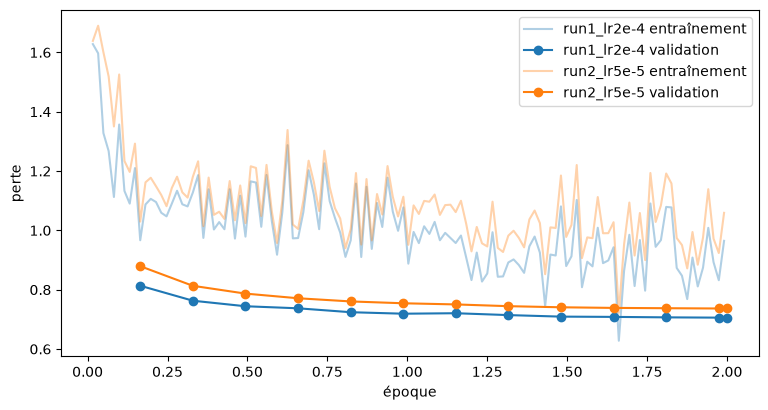

run1_lr2e-4 : meilleure perte de validation 0.706 (checkpoint-1200), 91 min
run2_lr5e-5 : meilleure perte de validation 0.737 (checkpoint-1200), 518 min


In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for run, color in ((run1, "tab:blue"), (run2, "tab:orange")):
    train_points = [(h["epoch"], h["loss"]) for h in run["history"] if "loss" in h]
    eval_points = [(h["epoch"], h["eval_loss"]) for h in run["history"] if "eval_loss" in h]
    ax.plot(*zip(*train_points), color=color, alpha=0.35, label=f"{run['name']} entraînement")
    ax.plot(*zip(*eval_points), color=color, marker="o", label=f"{run['name']} validation")
ax.set_xlabel("époque")
ax.set_ylabel("perte")
ax.legend()
plt.show()

for run in (run1, run2):
    print(f"{run['name']} : meilleure perte de validation {run['best_eval_loss']:.3f} ({run['best_checkpoint']}), "
          f"{run['minutes']:.0f} min")

Le run à 2e-4 est devant à chaque évaluation et finit à 0,706, contre 0,737 pour celui à 5e-5. Dans les deux runs, la perte de validation baisse jusqu'au bout de la deuxième époque, de moins en moins vite, sans remonter. Pas de sur-apprentissage visible. Le meilleur checkpoint est le 1200 dans les deux cas, presque le dernier. On garde le run à 2e-4.

La perte d'entraînement reste au-dessus de la validation et varie beaucoup d'un relevé à l'autre. C'est la moyenne des 10 derniers pas, donc de 80 exemples différents à chaque relevé, alors que la validation porte toujours sur les mêmes 290 exemples. Pour repérer le sur-apprentissage, on suit la courbe de validation.

Le second run a duré 518 minutes contre 91 pour le premier, avec le même nombre de pas. Dans MLflow, où chaque relevé est daté, le ralentissement commence juste après sa première évaluation. La mémoire de la carte était alors presque pleine d'après `nvidia-smi`, alors que PyTorch annonce 6,4 Go au maximum. Explication probable : PyTorch garde en réserve de la mémoire qu'il n'utilise plus, la carte déborde et Windows complète avec la mémoire de l'ordinateur, beaucoup plus lente.

In [11]:
best = min((run1, run2), key=lambda r: r["best_eval_loss"])
final_dir = OUT_DIR / "final"
shutil.copytree(OUT_DIR / best["name"] / "best", final_dir, dirs_exist_ok=True)
tokenizer.save_pretrained(final_dir)
info = {key: value for key, value in best.items() if key != "history"}
info.update({"model": MODEL, "dataset": DATA_REPO, "dataset_revision": DATA_REVISION, "seed": SEED,
             "lora": {"r": LORA.r, "alpha": LORA.lora_alpha, "dropout": LORA.lora_dropout}})
(final_dir / "run_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")
print("retenu :", best["name"], "->", final_dir)

retenu : run1_lr2e-4 -> ..\models\sft\final


## 7. Vérification rapide

Trois cas de triage de la validation : le modèle retenu répond-il au bon format, et s'arrête-t-il seul ? La mesure complète (niveaux justes, QCM, sécurité) se fait dans le notebook 06.

In [12]:
base = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16, device_map="cuda")
model = PeftModel.from_pretrained(base, final_dir)
model.eval()

for row in triage_val.select(range(3)):
    question, expected = row["messages"]
    prompt = tokenizer.apply_chat_template([question], tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt").input_ids.to("cuda")
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=500, do_sample=False)
    new_tokens = out[0, ids.shape[1]:]
    stopped = new_tokens[-1].item() == end_of_text
    print(question["content"][:150].replace("\n", " "), "[...]")
    print("attendu :", expected["content"].split("\n")[0])
    print("modèle  :", tokenizer.decode(new_tokens, skip_special_tokens=True)[:400])
    print(f"s'arrête seul : {'oui' if stopped else 'non'} ({len(new_tokens)} tokens)\n")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 10/310 [00:00<00:04, 72.62it/s]

Loading weights:   7%|▋         | 21/310 [00:00<00:03, 86.83it/s]

Loading weights:  12%|█▏        | 36/310 [00:00<00:02, 112.13it/s]

Loading weights:  17%|█▋        | 54/310 [00:00<00:02, 112.48it/s]

Loading weights:  23%|██▎       | 71/310 [00:00<00:02, 119.36it/s]

... (14 outputs left out)

Loading weights: 100%|██████████| 310/310 [00:02<00:00, 132.13it/s]

Cas clinique : Une femme de 62 ans est hospitalisée pour bilan d'un diabète récemment découvert. L'interrogatoire retrouve comme antécédents pathologi [...]
attendu : Niveau : urgence différée (tri 4 de l'échelle FRENCH).
modèle  : Niveau : urgence modérée (tri 3B de l'échelle FRENCH).
Explication : Patiente de 62 ans avec un antécédent de diabète récent, une glycémie à jeun à 8 mmol/l et une glycosurine à 15 mmol/24 h, ce qui correspond au tri 3B. Le motif principal est donc le diabète, sans critère de gravité. Les lésions cutanées (plaques érythémateuses luisantes, prurit, pustules blanchâtres) sont décrites comme modéréme
s'arrête seul : oui (283 tokens)



Cas clinique : Cet homme de 76 ans, ancien chauffeur, est atteint depuis un an d'une leucémie lymphoïde chronique qui fait l'objet d'une simple survei [...]
attendu : Niveau : urgence maximale (tri 2 de l'échelle FRENCH).
modèle  : Niveau : urgence maximale (tri 2 de l'échelle FRENCH).
Explication : Homme de 76 ans consultant pour une diarrhée fébrile à 40 °C depuis 4 jours, avec douleurs abdominales et signes de déshydratation (sécheresse des aisselles, langue saburrale, abdomen gargouillant et sensible, polyadénopathies superficielles). Le motif « Fièvre » a un tri par défaut de 2, et la fièvre à 40 °C avec signes de déshy
s'arrête seul : oui (260 tokens)



Cas clinique : Un patient âgé de 60 ans, est amené à la garde pour des douleurs épigastriques intenses avec vomissements, asthénie et obnubilation. L' [...]
attendu : Niveau : urgence maximale (tri 2 de l'échelle FRENCH).
modèle  : Niveau : urgence maximale (tri 2 de l'échelle FRENCH).
Explication : Le motif principal est une douleur épigastrique intense avec vomissements, qui est classé tri 3B par défaut. Le contexte de diabète et de HTA modérée fait craindre une insuffisance cardiaque, ce qui justifie le tri 2. La confusion avec obnubilation, la FC à 60/min et la TA à 90/70 mmHg (≤ 180) renforcent cette urgence.
Conduite :
s'arrête seul : oui (191 tokens)



## Bilan

- run retenu : learning rate 2e-4, checkpoint 1200, perte de validation 0,706. L'adaptateur LoRA et ses réglages (`run_info.json`) sont dans `models/sft/final`, les courbes et les paramètres dans MLflow (expérience `sft`)
- pas de sur-apprentissage visible sur deux époques, la perte de validation se stabilise à la fin
- sur les 3 cas de triage vérifiés, le format est respecté et le modèle s'arrête seul. 2 niveaux sur 3 sont ceux attendus. Le cas de la patiente diabétique avec des lésions de la peau est classé en urgence modérée au lieu de différée
- 3 cas ne suffisent pas pour juger. Les niveaux, les QCM et les contrôles de sécurité sont mesurés dans le notebook 06
- pour les runs du DPO, évaluation par paquets de 2 au lieu de 4 et mémoire de la carte affichée entre deux runs, pour éviter le ralentissement du second run